In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("/content/Wine_PCA.csv")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Alcohol,Flavanoids,Color_Intensity,Proline,Total_Phenols,Hue,Wine_Class
0,12.37,0.57,1.95,520.0,1.98,1.05,0
1,12.33,1.09,3.27,680.0,2.05,1.25,0
2,12.64,1.41,5.75,450.0,2.02,0.98,0
3,13.67,1.79,3.80,630.0,2.10,1.23,0
4,12.37,3.10,4.45,420.0,3.50,1.22,0


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nClass Distribution:")
print(df["Wine_Class"].value_counts().sort_index())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(119, 7)

Class Distribution:
Wine_Class
0    71
1    48
Name: count, dtype: int64

Missing Values:
Alcohol            0
Flavanoids         0
Color_Intensity    0
Proline            0
Total_Phenols      0
Hue                0
Wine_Class         0
dtype: int64


In [5]:
feature_names = [
    "Alcohol",
    "Flavanoids",
    "Color_Intensity",
    "Proline",
    "Total_Phenols",
    "Hue"
]

X = df[feature_names]

y = df["Wine_Class"]

print("Features:")
print(X.columns.tolist())

print("\nTarget: Wine_Class")

print("0 = Cultivar 2")
print("1 = Cultivar 3")

print("\nFeature data:")
display(X.head())

print("\nTarget distribution:")
print(y.value_counts())

Features:
['Alcohol', 'Flavanoids', 'Color_Intensity', 'Proline', 'Total_Phenols', 'Hue']

Target: Wine_Class
0 = Cultivar 2
1 = Cultivar 3

Feature data:


,Alcohol,Flavanoids,Color_Intensity,Proline,Total_Phenols,Hue
0,12.37,0.57,1.95,520.0,1.98,1.05
1,12.33,1.09,3.27,680.0,2.05,1.25
2,12.64,1.41,5.75,450.0,2.02,0.98
3,13.67,1.79,3.80,630.0,2.10,1.23
4,12.37,3.10,4.45,420.0,3.50,1.22



Target distribution:
Wine_Class
0    71
1    48
Name: count, dtype: int64


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 95
Testing samples: 24


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Standardization completed.")

print("\nFirst 5 standardized rows:")
print(X_train_scaled[:5])

Standardization completed.

First 5 standardized rows:
[[ 1.24487272 -1.30011917  0.32934296  0.1190907  -0.6693382  -0.40917658]
 [ 2.49640997 -0.27579466  3.07485731  0.6617102   1.47323212 -1.36936865]
 [ 0.42033053 -1.27543665 -0.08436468  0.25474558 -0.81459721 -0.5692086 ]
 [-0.5220034  -0.63369118 -0.66731636  2.08608639 -1.61352174 -0.02509976]
 [-0.83120672  0.06976059 -1.16000455  0.42431417  0.38378958  0.63103149]]


In [8]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train.shape[1])

print("Features after PCA:", X_train_pca.shape[1])

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Variance Retained:")
print(pca.explained_variance_ratio_.sum())

Original number of features: 6
Features after PCA: 2

Explained Variance Ratio:
[0.53822519 0.16607712]

Total Variance Retained:
0.7043023114221092


In [9]:
pca_df = pd.DataFrame(
    X_train_pca,
    columns=["PC1", "PC2"]
)

pca_df["Wine_Class"] = y_train.values

display(pca_df.head())

,PC1,PC2,Wine_Class
0,-1.728928,-0.370089,1
1,-2.777358,3.249105,1
2,-1.357441,-0.813640,1
3,-0.972359,-1.097315,0
4,1.195622,-0.335888,0


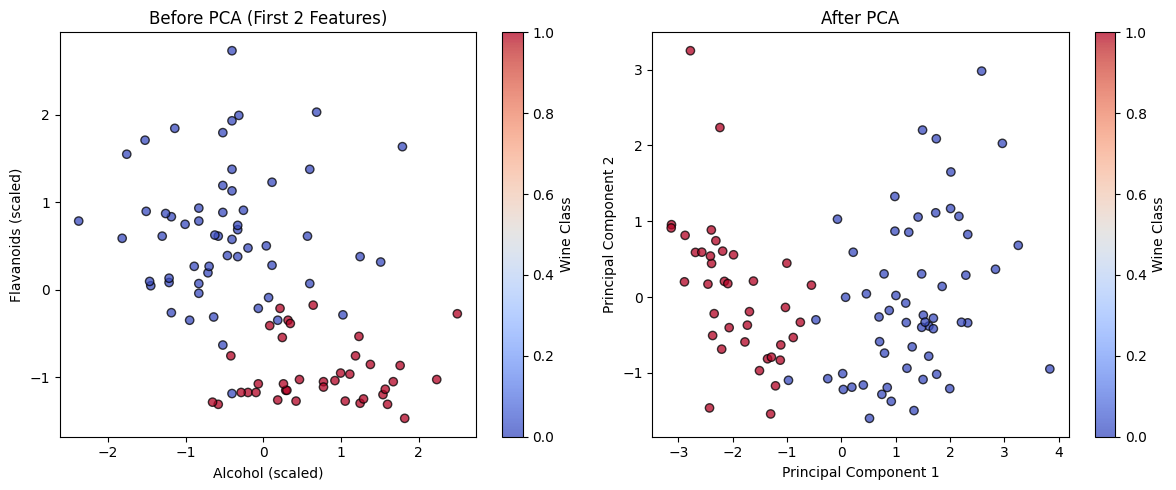

In [10]:
plt.figure(figsize=(12, 5))

# Before PCA
plt.subplot(1, 2, 1)

plt.scatter(
    X_train_scaled[:, 0],
    X_train_scaled[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.75,
    edgecolors="k"
)

plt.xlabel("Alcohol (scaled)")
plt.ylabel("Flavanoids (scaled)")
plt.title("Before PCA (First 2 Features)")
plt.colorbar(label="Wine Class")


# After PCA
plt.subplot(1, 2, 2)

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="coolwarm",
    alpha=0.75,
    edgecolors="k"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("After PCA")
plt.colorbar(label="Wine Class")

plt.tight_layout()
plt.show()

In [11]:
model = LogisticRegression(
    random_state=42
)

model.fit(
    X_train_pca,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
y_pred = model.predict(X_test_pca)

y_prob = model.predict_proba(
    X_test_pca
)[:, 1]

print("Predicted Classes:")
print(y_pred)

print("\nPrediction Probabilities:")
print(y_prob[:10])

Predicted Classes:
[0 0 0 1 1 1 1 0 0 1 0 1 0 0 0 0 1 0 0 0 1 1 0 1]

Prediction Probabilities:
[9.88982512e-05 7.86475161e-02 1.19229741e-03 7.80456264e-01
 9.81237143e-01 9.85780334e-01 9.84063669e-01 2.01916780e-03
 4.97460967e-03 9.97706571e-01]


In [13]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Test Accuracy: {accuracy:.2%}")

Test Accuracy: 100.00%


In [14]:
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2)),
    ("clf", LogisticRegression(random_state=42))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cv_pipeline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation accuracies:")
print(np.round(cv_scores, 3))

print(
    f"\nMean CV Accuracy: "
    f"{cv_scores.mean():.2%}"
)

print(
    f"Standard Deviation: "
    f"{cv_scores.std():.2%}"
)

Cross-validation accuracies:
[0.917 1.    1.    1.    1.   ]

Mean CV Accuracy: 98.33%
Standard Deviation: 3.33%


In [15]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[14  0]
 [ 0 10]]


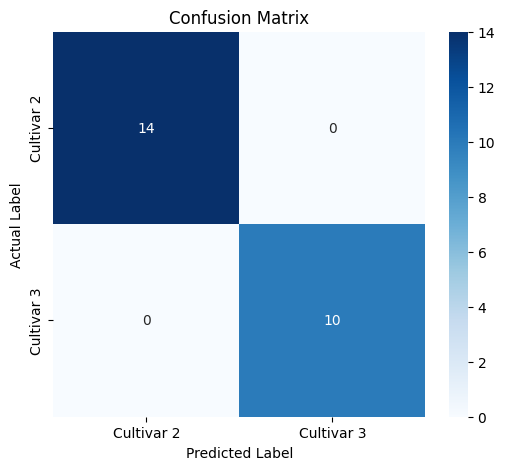

In [16]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Cultivar 2",
        "Cultivar 3"
    ],
    yticklabels=[
        "Cultivar 2",
        "Cultivar 3"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.title("Confusion Matrix")

plt.show()

In [17]:
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Cultivar 2",
            "Cultivar 3"
        ]
    )
)

Classification Report:
              precision    recall  f1-score   support

  Cultivar 2       1.00      1.00      1.00        14
  Cultivar 3       1.00      1.00      1.00        10

    accuracy                           1.00        24
   macro avg       1.00      1.00      1.00        24
weighted avg       1.00      1.00      1.00        24



In [18]:
component_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[
        "PC1",
        "PC2"
    ],
    index=feature_names
)

print("PCA Component Loadings:")

display(component_loadings)

PCA Component Loadings:


,PC1,PC2
Alcohol,-0.403675,0.306921
Flavanoids,0.475335,0.379829
Color_Intensity,-0.454741,0.386935
Proline,-0.278023,0.330633
Total_Phenols,0.368363,0.700715
Hue,0.437408,-0.107195


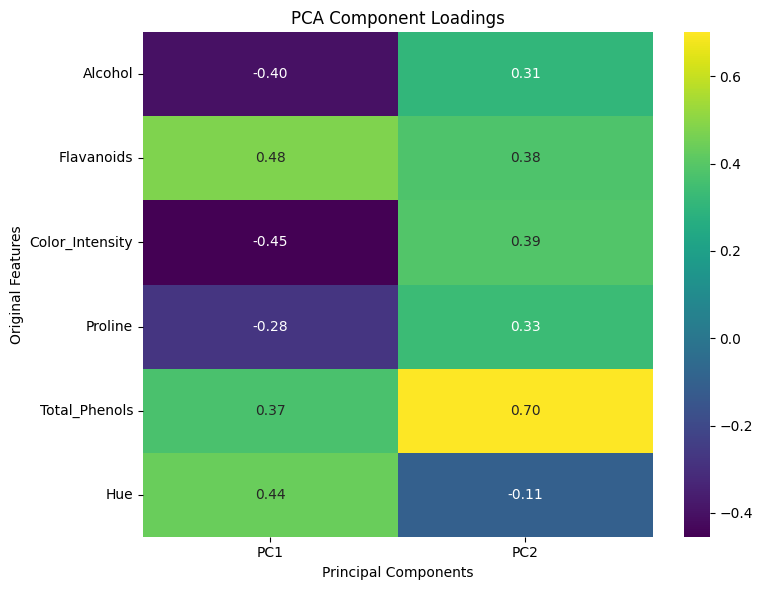

In [19]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    component_loadings,
    annot=True,
    cmap="viridis",
    fmt=".2f"
)

plt.title("PCA Component Loadings")

plt.xlabel("Principal Components")
plt.ylabel("Original Features")

plt.tight_layout()
plt.show()

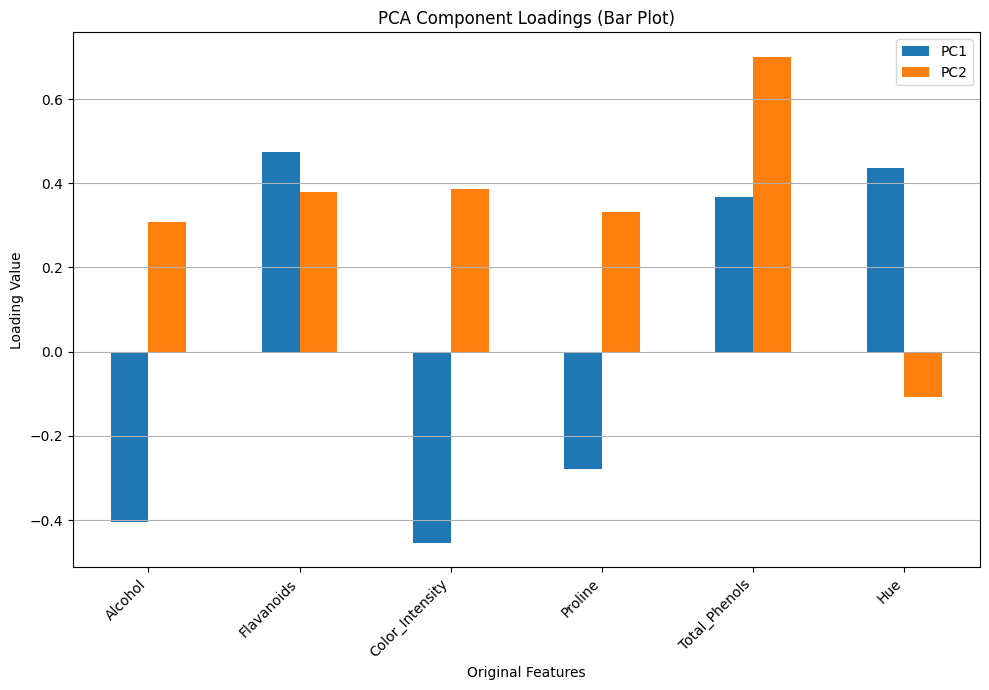

In [20]:
component_loadings.plot(
    kind="bar",
    figsize=(10, 7)
)

plt.title(
    "PCA Component Loadings (Bar Plot)"
)

plt.xlabel("Original Features")

plt.ylabel("Loading Value")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(axis="y")

plt.tight_layout()

plt.show()